# Thí nghiệm D E F trên PPG-DaLiA

Đặng Minh Tài · MSSV 23110148 · IOT-01CLC

| Thí nghiệm | Mô hình | Đối chứng |
|---|---|---|
| D | M1, PPG + ACC, CE thường | M1, CE có trọng số |
| E | M1, chỉ PPG, CE có trọng số | M1, PPG + ACC |
| F | CNN-HAR chỉ ACC | B2, PPG + ACC |

Chạy trên Colab GPU theo thứ tự, mount Drive chứa `MyDrive/M1_results`. D/E giữ λ đã chọn của M1 trong từng lượt. Kết quả bổ sung lưu tại `M1_results/DEF`; checkpoint hỗ trợ tiếp tục sau khi ngắt. Khi cache thiếu, dữ liệu được tải từ UCI.


In [1]:
# Colab T4 thường đã có các thư viện dưới đây. Nếu thiếu: %pip install -q tqdm requests numpy pandas scipy scikit-learn matplotlib torch
import os, sys, json, pickle, time, random, hashlib, platform, warnings, io
from pathlib import Path
import numpy as np, pandas as pd, scipy, torch, torch.nn as nn
import torch.nn.functional as F
from scipy.signal import butter, sosfiltfilt, resample_poly
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
print({'python':sys.version.split()[0], 'torch':torch.__version__, 'scipy':scipy.__version__, 'cuda':torch.version.cuda, 'device':torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})

{'python': '3.13.15', 'torch': '2.11.0+cu130', 'scipy': '1.16.3', 'cuda': '13.0', 'device': 'Tesla T4'}


## 1. Cấu hình và kết quả chính

Đọc split, thống kê Train và λ của M1; kiểm tra tính nhất quán của các file dùng làm đối chứng.


In [2]:
import shutil, gc, datetime, zipfile
from IPython.display import display, Markdown
BASE_DIR = Path('/content') if Path('/content').is_dir() else Path.cwd()
if not Path('/content').is_dir():
    raise RuntimeError('Notebook này dành cho Google Colab. Chọn GPU rồi Run all.')
from google.colab import drive
drive.mount('/content/drive')
MAIN = Path('/content/drive/MyDrive/M1_results')
DATA_ROOT = BASE_DIR/'PPG_FieldStudy'
SMOKE = False
OUT = MAIN/('DEF_SMOKE' if SMOKE else 'DEF')
OUT.mkdir(parents=True, exist_ok=True)
SESSION_TRAIN_MINUTES = 300  # None: không tự tạm dừng; không bảo đảm thời lượng Colab Free.
SEED, BATCH, MAX_EPOCHS, PATIENCE = 42, 64, 100, 10
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type != 'cuda':
    raise RuntimeError('Chưa có GPU. Chọn Runtime > Change runtime type > GPU rồi chạy lại.')
EXPERIMENT_VERSION = 'M1_DEF_2026_10_04_v1'
CLASS_NAMES = ['Sitting','Stairs','Table soccer','Cycling','Driving','Lunch','Walking','Working']
GROUPS = [[1,2,3],[4,5,6],[7,8,9],[10,11,12],[13,14,15]]
SPLITS = [([s for g in range(5) if g not in (t,(t+1)%5) for s in GROUPS[g]],
           GROUPS[(t+1)%5], GROUPS[t]) for t in range(5)]
required = ['preprocess_config.json','train_only_statistics.json','selected_before_test.json',
            'validation_runs.csv','test_predictions.csv','window_audit.csv']
missing = [name for name in required if not (MAIN/name).is_file()]
if missing:
    raise FileNotFoundError(f'Thiếu kết quả gốc: {missing}. Khôi phục M1_results vào MyDrive trước khi chạy.')
PREP_CONFIG = json.loads((MAIN/'preprocess_config.json').read_text())
PREP_HASH = hashlib.sha256(json.dumps(PREP_CONFIG,sort_keys=True).encode()).hexdigest()[:12]
HR_T0_SECONDS = float(PREP_CONFIG['hr_t0'])
ACTIVITY_CODE_TO_CLASS = {int(k):int(v) for k,v in PREP_CONFIG['mapping'].items()}
assert ACTIVITY_CODE_TO_CLASS == {i:i-1 for i in range(1,9)}
for key,expected in dict(fs_bvp=64,fs_acc=32,fs_activity=4,window=8,stride=2,butter_N=4).items():
    assert PREP_CONFIG[key] == expected, f'Cấu hình gốc khác tại {key}'
assert PREP_CONFIG['ppg_band'] == [0.5,8]
assert len(PREP_CONFIG['dataset_sha256']) == 15
norms = json.loads((MAIN/'train_only_statistics.json').read_text())
selection_main = pd.DataFrame(json.loads((MAIN/'selected_before_test.json').read_text()))
main_runs = pd.read_csv(MAIN/'validation_runs.csv')
main_pred = pd.read_csv(MAIN/'test_predictions.csv')
assert len(main_runs)==25 and len(selection_main)==15
assert not main_runs.tag.str.contains('SMOKE').any()
assert not selection_main.duplicated(['fold','mode']).any()
assert set(selection_main['mode']) == {'B1','B2','M1'}
for row in selection_main.itertuples():
    best=main_runs[(main_runs.fold==row.fold)&(main_runs['mode']==row.mode)].sort_values(['score','lam']).iloc[0]
    assert row.tag==best.tag and row.epoch==best.epoch
    assert np.isclose(row.score,best.score)
LAMBDA_BY_FOLD = {int(r.fold):float(r.lam) for r in selection_main[selection_main['mode']=='M1'].itertuples()}
assert set(LAMBDA_BY_FOLD)==set(range(1,6))
assert all(v in (0.1,1.,10.) for v in LAMBDA_BY_FOLD.values())
assert set(main_pred.model)=={'B1','B2','M1'}
for mode,g in main_pred.groupby('model'):
    assert not g.duplicated(['subject','window_index']).any()
    assert set(g.subject)==set(range(1,16))
    assert (g.fold==((g.subject-1)//3+1)).all()
reference=main_pred[main_pred.model=='M1'].set_index(['subject','window_index']).sort_index()
for mode,g in main_pred.groupby('model'):
    aligned=g.set_index(['subject','window_index']).reindex(reference.index)
    assert len(g)==len(reference)
    np.testing.assert_array_equal(aligned.class_true,reference.class_true)
    np.testing.assert_allclose(aligned.hr_true,reference.hr_true,atol=1e-4,rtol=0)
BASELINE_HASHES = {name:hashlib.sha256((MAIN/name).read_bytes()).hexdigest() for name in required}
RUN_CONFIG = dict(version=EXPERIMENT_VERSION,preprocess_hash=PREP_HASH,baseline_sha256=BASELINE_HASHES,
                  lambdas=LAMBDA_BY_FOLD,splits=SPLITS,seed=SEED,batch=BATCH,max_epochs=MAX_EPOCHS,
                  patience=PATIENCE,smoke=SMOKE,optimizer='AdamW',lr=1e-3,weight_decay=1e-4)
RUN_HASH = hashlib.sha256(json.dumps(RUN_CONFIG,sort_keys=True).encode()).hexdigest()
config_path=OUT/'experiment_config.json'
if config_path.exists() and json.loads(config_path.read_text()) != json.loads(json.dumps(RUN_CONFIG)):
    raise RuntimeError('Thư mục DEF chứa cấu hình khác. Dùng thư mục mới để tránh trộn thí nghiệm.')
config_path.write_text(json.dumps(RUN_CONFIG,indent=2),encoding='utf-8')
display(pd.DataFrame([dict(fold=i+1,train=tr,validation=va,test=te,lambda_DE=LAMBDA_BY_FOLD[i+1])
                      for i,(tr,va,te) in enumerate(SPLITS)]))
print('GPU:',torch.cuda.get_device_name(0),'| cache:',PREP_HASH,'| đầu ra:',OUT)

Mounted at /content/drive


,fold,train,validation,test,lambda_DE
0,1,"[7, 8, 9, 10, 11, 12, 13, 14, 15]","[4, 5, 6]","[1, 2, 3]",0.1
1,2,"[1, 2, 3, 10, 11, 12, 13, 14, 15]","[7, 8, 9]","[4, 5, 6]",1.0
2,3,"[1, 2, 3, 4, 5, 6, 13, 14, 15]","[10, 11, 12]","[7, 8, 9]",0.1
3,4,"[1, 2, 3, 4, 5, 6, 7, 8, 9]","[13, 14, 15]","[10, 11, 12]",1.0
4,5,"[4, 5, 6, 7, 8, 9, 10, 11, 12]","[1, 2, 3]","[13, 14, 15]",1.0


GPU: Tesla T4 | cache: 222db9358a24 | đầu ra: /content/drive/MyDrive/M1_results/DEF


## 2. Cache và dữ liệu

Dùng lại cache bốn kênh. Nếu thiếu, tải dữ liệu và kiểm tra SHA256 trước khi áp dụng cùng quy trình tiền xử lý. E/F chọn kênh từ cache tại DataLoader.


In [4]:
CACHE = MAIN/'cache_64hz'
CACHE.mkdir(exist_ok=True)
missing_cache = [s for s in range(1,16) if not (CACHE/f'S{s}_{PREP_HASH}.npz').is_file()]
def subject_path(s):
    candidates = [DATA_ROOT/f'S{s}'/f'S{s}.pkl', DATA_ROOT/f'S{s}.pkl']
    return next((p for p in candidates if p.is_file()), candidates[0])

def load_subject(s):
    p=subject_path(s)
    if not p.exists(): raise FileNotFoundError(f'Thiếu {p}; tải và giải nén data.zip của UCI trước.')
    with p.open('rb') as f: d=pickle.load(f, encoding='latin1')
    bvp=np.asarray(d['signal']['wrist']['BVP']).reshape(-1)
    acc=np.asarray(d['signal']['wrist']['ACC'])
    activity=np.asarray(d['activity']).reshape(-1)
    hr=np.asarray(d['label']).reshape(-1)
    if acc.ndim!=2 or acc.shape[1]!=3: raise ValueError(f'S{s}: ACC phải là (T,3), có {acc.shape}')
    return bvp,acc,activity,hr


if missing_cache:
    if not all(subject_path(s).is_file() for s in range(1,16)) and shutil.disk_usage(BASE_DIR).free<25_000_000_000:
        raise RuntimeError('Cần khoảng 25 GB ổ trống để tải và giải nén đủ dữ liệu gốc. Dữ liệu sẽ nằm ở runtime, không nằm trên Drive.')
    import re, shutil, zipfile, requests

    UCI_ZIP_URL = 'https://archive.ics.uci.edu/static/public/495/ppg%2Bdalia.zip'
    README_URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00495/readme.pdf'
    ARCHIVE_DIR = BASE_DIR/'ppg_dalia_download'
    ARCHIVE_DIR.mkdir(parents=True, exist_ok=True)
    OUTER_ZIP = ARCHIVE_DIR/'ppg_dalia_uci.zip'
    INNER_ZIP = ARCHIVE_DIR/'data.zip'

    def complete_data(root):
        return all((root/f'S{s}'/f'S{s}.pkl').is_file() and (root/f'S{s}'/f'S{s}.pkl').stat().st_size>0 for s in range(1,16))

    def copy_progress(reader, writer, total, description):
        with tqdm(total=total, unit='B', unit_scale=True, desc=description, leave=False) as bar:
            while chunk := reader.read(1024*1024):
                writer.write(chunk); bar.update(len(chunk))

    def download_resumable(url, target, attempts=5):
        # Tải tiếp qua HTTP Range; nếu server trả 200 thì ghi lại từ đầu, tránh nối file sai.
        for attempt in range(1,attempts+1):
            offset=target.stat().st_size if target.exists() else 0
            headers={'Range':f'bytes={offset}-'} if offset else {}
            try:
                with requests.get(url,stream=True,timeout=(20,120),headers=headers) as response:
                    if response.status_code==416 and zipfile.is_zipfile(target): return
                    response.raise_for_status()
                    resume=offset>0 and response.status_code==206
                    if resume and not response.headers.get('Content-Range','').startswith(f'bytes {offset}-'):
                        raise RuntimeError('Máy chủ trả Content-Range không khớp file tải dở.')
                    mode='ab' if resume else 'wb'
                    total=int(response.headers.get('Content-Length',0)) or None
                    if total is not None: total+=offset if resume else 0
                    with target.open(mode) as out, tqdm(total=total,initial=offset if resume else 0,
                            unit='B',unit_scale=True,desc=f'Tải UCI ({attempt}/{attempts})') as bar:
                        for chunk in response.iter_content(chunk_size=4*1024*1024):
                            if chunk: out.write(chunk);bar.update(len(chunk))
                if not zipfile.is_zipfile(target): raise zipfile.BadZipFile('Tệp tải xong không có cấu trúc ZIP')
                return
            except (requests.RequestException, zipfile.BadZipFile) as err:
                if attempt==attempts: raise RuntimeError(f'Tải UCI thất bại sau {attempts} lần: {err}') from err
                print(f'Mạng ngắt hoặc ZIP chưa đủ ({err}); thử tiếp từ byte {target.stat().st_size if target.exists() else 0}.')
                time.sleep(min(2*attempt,10))

    def extract_pickles(inner_path, root):
        # Đích do notebook tự tạo; không dùng đường dẫn từ ZIP để tránh ghi ra ngoài root.
        with zipfile.ZipFile(inner_path) as z:
            found={}
            for member in z.infolist():
                m=re.search(r'(?:^|/)S(1[0-5]|[1-9])/S\1\.pkl$',member.filename)
                if m:
                    s=int(m.group(1))
                    if s in found: raise RuntimeError(f'ZIP chứa hai bản S{s}.pkl.')
                    found[s]=member
            if set(found)!=set(range(1,16)):
                raise RuntimeError(f'ZIP thiếu pickle: {sorted(set(range(1,16))-set(found))}. Tên đầu: {z.namelist()[:10]}')
            root.mkdir(parents=True,exist_ok=True)
            for s in tqdm(range(1,16),desc='Giải nén subject',unit='người'):
                dst=root/f'S{s}'/f'S{s}.pkl';dst.parent.mkdir(exist_ok=True)
                if dst.is_file() and dst.stat().st_size==found[s].file_size: continue
                tmp=dst.with_suffix('.pkl.part')
                with z.open(found[s]) as reader, tmp.open('wb') as writer:
                    copy_progress(reader,writer,found[s].file_size,f'S{s}.pkl')
                if tmp.stat().st_size!=found[s].file_size: raise IOError(f'S{s} chưa giải nén đủ.')
                tmp.replace(dst)

    if not complete_data(DATA_ROOT):
        if not INNER_ZIP.exists():
            if not zipfile.is_zipfile(OUTER_ZIP):
                free_gb=shutil.disk_usage(BASE_DIR).free/1e9
                if free_gb<7: raise RuntimeError(f'Chỉ còn {free_gb:.1f} GB; cần khoảng 7 GB ổ trống trước khi tải.')
                download_resumable(UCI_ZIP_URL,OUTER_ZIP)
            with zipfile.ZipFile(OUTER_ZIP) as z:
                candidates=[m for m in z.infolist() if m.filename.lower().endswith('/data.zip') or m.filename.lower()=='data.zip']
                if len(candidates)!=1: raise RuntimeError(f'ZIP ngoài cần đúng một data.zip; thấy {z.namelist()[:15]}')
                with z.open(candidates[0]) as reader, INNER_ZIP.with_suffix('.zip.part').open('wb') as writer:
                    copy_progress(reader,writer,candidates[0].file_size,'Tách data.zip')
                INNER_ZIP.with_suffix('.zip.part').replace(INNER_ZIP)
                for item in z.infolist():
                    if item.filename.lower().endswith('readme.pdf'):
                        DATA_ROOT.mkdir(parents=True,exist_ok=True)
                        with z.open(item) as reader, (DATA_ROOT/'UCI_readme.pdf').open('wb') as writer:
                            shutil.copyfileobj(reader,writer)
                        break
            OUTER_ZIP.unlink()  # lấy lại ổ trống trước khi giải nén subject
        if not zipfile.is_zipfile(INNER_ZIP):
            raise RuntimeError(f'data.zip không hợp lệ: {INNER_ZIP}. Xóa file này rồi chạy lại.')
        extract_pickles(INNER_ZIP,DATA_ROOT)
        if not complete_data(DATA_ROOT): raise RuntimeError('Chưa đủ 15 pickle sau giải nén.')
        INNER_ZIP.unlink()
    # README chỉ 799 kB, tải bổ sung nếu bản ZIP không kèm theo.
    if not (DATA_ROOT/'UCI_readme.pdf').exists():
        r=requests.get(README_URL,timeout=(20,120));r.raise_for_status()
        (DATA_ROOT/'UCI_readme.pdf').write_bytes(r.content)
    print('Sẵn sàng:',DATA_ROOT,'| 15/15 subject | README:',DATA_ROOT/'UCI_readme.pdf')

    for s in tqdm(range(1,16),desc='Xác minh SHA256 dữ liệu gốc',unit='người'):
        h=hashlib.sha256()
        with subject_path(s).open('rb') as stream:
            while chunk:=stream.read(4*1024*1024):h.update(chunk)
        assert h.hexdigest()==PREP_CONFIG['dataset_sha256'][f'S{s}'], f'S{s}: dữ liệu khác bản A/B/C'
def prepare_subject(s, force=False):
    cache=CACHE/f'S{s}_{PREP_HASH}.npz'; profile=CACHE/f'S{s}_{PREP_HASH}_audit.csv'
    if cache.exists() and profile.exists() and not force:
        with np.load(cache) as z: return {k:z[k] for k in z.files}, pd.read_csv(profile)
    bvp,acc,act,hr=load_subject(s)
    if not (np.isfinite(bvp).all() and np.isfinite(acc).all()): raise ValueError(f'S{s}: tín hiệu chứa NaN/Inf; cần ghi nhận lỗi dữ liệu.')
    sos=butter(4,[0.5,8],btype='bandpass',fs=64,output='sos')
    ppg=sosfiltfilt(sos,bvp).astype(np.float32)
    acc64=resample_poly(acc,2,1,axis=0).astype(np.float32)
    x_list=[]; ids=[]; y_hr=[]; y_act=[]; rows=[]
    for i,y in enumerate(hr):
        t=HR_T0_SECONDS+2*i; e=t+8
        # exact integer sample boundaries for this 64/4 Hz grid
        a64=round(t*64); b64=a64+512; a4=round(t*4); b4=a4+32
        reason='kept'; c=-1
        if not np.isfinite(y): reason='invalid_hr'
        elif a64<0 or b64>len(ppg) or b64>len(acc64) or a4<0 or b4>len(act): reason='out_of_bounds'
        else:
            codes=act[a4:b4]
            if not np.isfinite(codes).all() or not np.all(codes==codes[0]): reason='transition_or_mixed'
            elif float(codes[0]) not in ACTIVITY_CODE_TO_CLASS: reason='out_of_scope'
            else: c=ACTIVITY_CODE_TO_CLASS[int(codes[0])]
        if reason=='kept':
            x=np.concatenate([ppg[a64:b64,None],acc64[a64:b64]],axis=1).T
            if not np.isfinite(x).all(): reason='invalid_signal'
            else:
                x_list.append(x); ids.append(i); y_hr.append(float(y)); y_act.append(c)
        rows.append((f'S{s}',i,t,e,float(y),c,reason))
    meta=pd.DataFrame(rows,columns=['subject_id','window_index','start_s','end_s','hr_bpm','class_id','status'])
    assert len(ids)==len(set(ids))
    X=np.stack(x_list).astype(np.float32) if x_list else np.empty((0,4,512),np.float32)
    data=dict(X=X, idx=np.array(ids,np.int32), hr=np.array(y_hr,np.float32), cls=np.array(y_act,np.int64))
    np.savez(cache,**data); meta.to_csv(profile,index=False)
    return data,meta


prepared={}
for s in tqdm(range(1,16),desc='Nhận cache và kiểm tra cửa sổ',unit='người'):
    cache=CACHE/f'S{s}_{PREP_HASH}.npz'
    if cache.is_file():
        with np.load(cache,allow_pickle=False) as z:d={k:z[k] for k in z.files}
    else:
        d,_=prepare_subject(s)
    assert d['X'].shape==(len(d['hr']),4,512)
    assert len(d['idx'])==len(d['cls'])==len(d['hr'])
    assert np.isfinite(d['X']).all() and np.isfinite(d['hr']).all()
    ref=main_pred[(main_pred.model=='M1')&(main_pred.subject==s)].sort_values('window_index')
    order=np.argsort(d['idx'])
    np.testing.assert_array_equal(d['idx'][order],ref.window_index.to_numpy())
    np.testing.assert_array_equal(d['cls'][order],ref.class_true.to_numpy())
    np.testing.assert_allclose(d['hr'][order],ref.hr_true.to_numpy(),atol=1e-4,rtol=0)
    prepared[s]=d
expected_keys={(s,int(i)) for s,d in prepared.items() for i in d['idx']}
for mode,g in main_pred.groupby('model'):
    assert set(map(tuple,g[['subject','window_index']].to_numpy()))==expected_keys
for fold,(tr,va,te) in enumerate(SPLITS,1):
    n=norms[str(fold)];y=np.concatenate([prepared[s]['hr'] for s in tr]);c=np.concatenate([prepared[s]['cls'] for s in tr])
    count=np.bincount(c,minlength=8)
    np.testing.assert_array_equal(count,n['class_count']);assert np.all(count>0)
    np.testing.assert_allclose(len(c)/(8*count),n['weights'],rtol=1e-6)
    np.testing.assert_allclose([y.mean(),max(y.std(),1e-6)],[n['hr_mean'],n['hr_std']],rtol=1e-6)
    assert len(n['mean'])==len(n['std'])==4 and np.all(np.asarray(n['std'])>0)
print('Cửa sổ hợp lệ:',len(expected_keys),'| dùng đúng thống kê Train của A/B/C')
env=dict(recorded_at=datetime.datetime.now(datetime.timezone.utc).isoformat(),python=sys.version,
         torch=torch.__version__,numpy=np.__version__,scipy=scipy.__version__,cuda=torch.version.cuda,
         gpu=torch.cuda.get_device_name(0),gpu_bytes=torch.cuda.get_device_properties(0).total_memory,
         cpu=platform.processor(),ram_bytes=os.sysconf('SC_PAGE_SIZE')*os.sysconf('SC_PHYS_PAGES'),
         run_hash=RUN_HASH,seed=SEED)
(OUT/f'environment_{time.time_ns()}.json').write_text(json.dumps(env,indent=2),encoding='utf-8')

Cửa sổ hợp lệ: 46763 | dùng đúng thống kê Train của A/B/C


399

## 3. Mô hình và chỉ số

D thay trọng số CE; E bỏ ba kênh ACC; F chỉ giữ ACC và đầu HAR. Các mô hình được khởi tạo từ đầu, giữ bề rộng backbone và cấu trúc đầu dự đoán.


In [5]:
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False

class CNN(nn.Module):
    def __init__(self,mode='M1',in_channels=4):
        super().__init__(); self.mode=mode
        layers=[]; prev=in_channels
        for width in [32,64,128,256]:
            layers += [nn.Conv1d(prev,width,9,padding=4,bias=False),nn.BatchNorm1d(width),nn.ReLU(),nn.MaxPool1d(2)]
            prev=width
        self.backbone=nn.Sequential(*layers,nn.AdaptiveAvgPool1d(1))
        if mode in ('B1','M1'): self.hr_head=nn.Sequential(nn.Linear(256,64),nn.ReLU(),nn.Dropout(.2),nn.Linear(64,1))
        if mode in ('B2','M1'): self.har_head=nn.Sequential(nn.Linear(256,64),nn.ReLU(),nn.Dropout(.2),nn.Linear(64,8))
    def forward(self,x):
        h=self.backbone(x).squeeze(-1)
        return (self.hr_head(h).squeeze(-1) if hasattr(self,'hr_head') else None,
                self.har_head(h) if hasattr(self,'har_head') else None)

params={mode:sum(p.numel() for p in CNN(mode).parameters() if p.requires_grad) for mode in ('B1','B2','M1')}
print(params,'B1+B2',params['B1']+params['B2'])
assert params=={'B1':405697,'B2':406152,'M1':422665}, params
assert CNN('M1')(torch.randn(2,4,512))[0].shape==(2,)

class WindowDataset(Dataset):
    def __init__(self,subjects,mean,std,mu,sy,channels):
        self.refs=[(s,i) for s in subjects for i in range(len(prepared[s]['X']))]
        self.channels=list(channels); self.mean=mean[:,None]; self.std=std[:,None]; self.mu=mu; self.sy=sy
    def __len__(self): return len(self.refs)
    def __getitem__(self,j):
        s,i=self.refs[j]; d=prepared[s]
        return (torch.from_numpy((((d['X'][i]-self.mean)/self.std)[self.channels]).astype(np.float32)),
                torch.tensor((float(d['hr'][i])-self.mu)/self.sy,dtype=torch.float32),
                torch.tensor(int(d['cls'][i]),dtype=torch.long),s,int(d['idx'][i]),float(d['hr'][i]))

def predict(model,loader,mu,sy):
    model.eval(); rows=[]
    with torch.inference_mode():
        for x,_,c,s,idx,hr in tqdm(loader,desc='Dự đoán Validation / Test',unit='batch',leave=False):
            h,a=model(x.to(DEVICE)); hp=(h.cpu().numpy()*sy+mu) if h is not None else [np.nan]*len(s)
            cp=a.argmax(1).cpu().numpy() if a is not None else [-1]*len(s)
            rows.extend(zip(np.asarray(s),idx.numpy(),hr.numpy(),c.numpy(),hp,cp))
    return pd.DataFrame(rows,columns=['subject','window_index','hr_true','class_true','hr_pred','class_pred'])

def metrics(df,mode,sy):
    result={}
    if mode!='B2':
        err=(df.hr_true-df.hr_pred).abs()
        result['mae_pooled']=float(err.mean())
        result['mae_subject']=float(df.assign(err=err).groupby('subject').err.mean().mean())
    if mode!='B1':
        result['accuracy']=float(accuracy_score(df.class_true,df.class_pred))
        result['macro_f1']=float(f1_score(df.class_true,df.class_pred,labels=list(range(8)),average='macro',zero_division=0))
    result['criterion']=(result['mae_subject'] if mode=='B1' else 1-result['macro_f1'] if mode=='B2' else result['mae_subject']/sy+1-result['macro_f1'])
    return result

VARIANTS={
    'D':dict(mode='M1',channels=[0,1,2,3],weighted=False,baseline='M1'),
    'E':dict(mode='M1',channels=[0],weighted=True,baseline='M1'),
    'F':dict(mode='B2',channels=[1,2,3],weighted=True,baseline='B2'),
}
def make_model(variant):
    v=VARIANTS[variant]
    return CNN(v['mode'],len(v['channels']))
def loader(subjects,n,variant,shuffle=False):
    return DataLoader(WindowDataset(subjects,np.asarray(n['mean'],np.float32),np.asarray(n['std'],np.float32),
                      n['hr_mean'],n['hr_std'],VARIANTS[variant]['channels']),
                      batch_size=BATCH,shuffle=shuffle,num_workers=0)
def objective(h,a,y,c,variant,lam,w):
    ce=F.cross_entropy(a,c,weight=w if VARIANTS[variant]['weighted'] else None)
    return ce if variant=='F' else F.l1_loss(h,y)+lam*ce
for variant,v in VARIANTS.items():
    model=make_model(variant);count=sum(p.numel() for p in model.parameters())
    assert count=={'D':422665,'E':421801,'F':405864}[variant]
    h,a=model(torch.zeros(2,len(v['channels']),512));assert a.shape==(2,8)
    assert (h is None) if variant=='F' else h.shape==(2,)
    print(variant,'| kênh:',v['channels'],'| tham số:',count)
del model;gc.collect()

{'B1': 405697, 'B2': 406152, 'M1': 422665} B1+B2 811849
D | kênh: [0, 1, 2, 3] | tham số: 422665
E | kênh: [0] | tham số: 421801
F | kênh: [1, 2, 3] | tham số: 405864


0

## 4. Huấn luyện

Chạy năm lượt cho mỗi biến thể. D/E chọn epoch theo J; F theo 1 − Macro-F1. Checkpoint lưu mô hình, optimizer, scheduler và trạng thái ngẫu nhiên sau mỗi epoch. Chạy lại từ đầu để tiếp tục sau khi ngắt; epoch chưa lưu sẽ chạy lại.


In [6]:
class TrainingPaused(RuntimeError):
    pass

def _save_atomic(payload, destination):
    # Ghi vào ổ tạm trước, copy lên Drive bằng tên .part rồi đổi tên.
    local_tmp=BASE_DIR/f'.{destination.name}.writing'
    remote_tmp=destination.with_suffix(destination.suffix+'.part')
    try:
        torch.save(payload,local_tmp)
        shutil.copy2(local_tmp,remote_tmp)
        remote_tmp.replace(destination)
    finally:
        local_tmp.unlink(missing_ok=True)

def _rng_state():
    return dict(python=random.getstate(),numpy=np.random.get_state(),torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None)

def _restore_rng(state):
    random.setstate(state['python']);np.random.set_state(state['numpy']);torch.set_rng_state(state['torch'])
    if torch.cuda.is_available() and state['cuda'] is not None: torch.cuda.set_rng_state_all(state['cuda'])

def train_one(fold,variant,lam,train_ids,val_ids,n,session_started):
    mode=VARIANTS[variant]['mode'];mean=np.asarray(n['mean'],np.float32);std=np.asarray(n['std'],np.float32)
    mu=n['hr_mean'];sy=n['hr_std'];weights=n['weights']
    tag=f'fold{fold}_{variant}'
    path=OUT/f'{tag}.pt';resume_path=OUT/f'{tag}_resume.pt';histpath=OUT/f'{tag}_history.csv'
    signature=dict(run_hash=RUN_HASH,fold=fold,variant=variant,lam=lam,
                   train_ids=train_ids,val_ids=val_ids,smoke=SMOKE)
    if path.exists():
        ck=torch.load(path,map_location='cpu',weights_only=False)
        if not ck.get('complete') or ck.get('signature')!=signature:
            raise RuntimeError(f'{path}: checkpoint khác cấu hình hoặc chưa hoàn chỉnh.')
        tqdm.write(f'{tag}: đã xong, chọn epoch {ck["epoch"]}')
        return dict(tag=tag,path=str(path),score=ck['score'],epoch=ck['epoch'],fold=fold,variant=variant,mode=mode,lam=lam)
    seed_everything()
    model=make_model(variant).to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=1e-3,weight_decay=1e-4)
    sched=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='min',factor=.5,patience=5)
    tr=loader(train_ids,n,variant,shuffle=True)
    va=loader(val_ids,n,variant)
    w=torch.tensor(weights,dtype=torch.float32,device=DEVICE)
    best=float('inf');stale=0;history=[];best_state=None;best_epoch=-1;start_epoch=0
    max_epochs=2 if SMOKE else MAX_EPOCHS
    if resume_path.exists():
        ck=torch.load(resume_path,map_location='cpu',weights_only=False)
        if ck.get('signature')!=signature:
            raise RuntimeError(f'{resume_path} có cấu hình khác, không thể tiếp tục an toàn.')
        model.load_state_dict(ck['model']);opt.load_state_dict(ck['optimizer']);sched.load_state_dict(ck['scheduler'])
        best=ck['best'];stale=ck['stale'];history=ck['history'];best_state=ck['best_state'];best_epoch=ck['best_epoch']
        start_epoch=ck['next_epoch'];_restore_rng(ck['rng'])
        tqdm.write(f'{tag}: tiếp tục từ epoch {start_epoch+1}/{max_epochs}; best={best:.4f}')
    if stale>=PATIENCE:start_epoch=max_epochs
    epoch_bar=tqdm(range(start_epoch,max_epochs),desc=f'{tag} [Validation]',unit='epoch',leave=True)
    for epoch in epoch_bar:
        model.train();total=0;seen=0
        batch_bar=tqdm(tr,desc=f'epoch {epoch+1}/{max_epochs}',unit='batch',leave=False)
        for x,y,c,*_ in batch_bar:
            x,y,c=x.to(DEVICE),y.to(DEVICE),c.to(DEVICE)
            opt.zero_grad(set_to_none=True);h,a=model(x)
            loss=objective(h,a,y,c,variant,lam,w)
            loss.backward();opt.step();total+=loss.item()*len(x);seen+=len(x)
            batch_bar.set_postfix(loss=f'{total/seen:.4f}')
        pred=predict(model,va,mu,sy);met=metrics(pred,mode,sy)
        score=met['criterion']
        if not np.isfinite(score):raise RuntimeError(f'{tag}: Validation không hữu hạn.')
        sched.step(score)
        history.append(dict(epoch=epoch+1,train_loss=total/seen,lr=opt.param_groups[0]['lr'],**met))
        if score<best-1e-8:
            best=score;stale=0;best_epoch=epoch+1
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:stale+=1
        epoch_bar.set_postfix(train_loss=f'{total/seen:.4f}',val=f'{score:.4f}',best=f'{best:.4f}',patience=f'{stale}/{PATIENCE}')
        pd.DataFrame(history).to_csv(histpath,index=False)
        # Lưu cả trạng thái huấn luyện sau mỗi epoch. Nếu ngắt giữa epoch, chạy lại từ đầu epoch đó.
        _save_atomic(dict(signature=signature,model=model.state_dict(),optimizer=opt.state_dict(),
                          scheduler=sched.state_dict(),rng=_rng_state(),next_epoch=epoch+1,
                          best=best,stale=stale,best_epoch=best_epoch,best_state=best_state,
                          history=history),resume_path)
        if stale>=PATIENCE:break
        if epoch+1<max_epochs and SESSION_TRAIN_MINUTES is not None and (time.monotonic()-session_started)/60>=SESSION_TRAIN_MINUTES:
            raise TrainingPaused(f'Đã lưu {tag} đến epoch {epoch+1}. Colab có thể ngắt phiên; Run all lại để tiếp tục.')
    if best_state is None:raise RuntimeError(f'{tag}: không có checkpoint hợp lệ.')
    _save_atomic(dict(state=best_state,mean=mean,std=std,mu=mu,sy=sy,score=best,epoch=best_epoch,
                      signature=signature,variant=variant,mode=mode,lam=lam,fold=fold,train_ids=train_ids,val_ids=val_ids,
                      config_hash=PREP_HASH,experiment_version=EXPERIMENT_VERSION,
                      complete=True,smoke=SMOKE,history=str(histpath)),path)
    resume_path.unlink(missing_ok=True)
    return dict(tag=tag,path=str(path),score=best,epoch=best_epoch,fold=fold,variant=variant,mode=mode,lam=lam)


runs=[];session_started=time.monotonic()
try:
    with tqdm(total=15,desc='D E F tổng tiến độ',unit='mô hình') as progress:
        for variant in ('D','E','F'):
            for fold,(tr,va,te) in enumerate(SPLITS,1):
                lam=LAMBDA_BY_FOLD[fold] if variant!='F' else 1.0
                runs.append(train_one(fold,variant,lam,tr,va,norms[str(fold)],session_started))
                pd.DataFrame(runs).to_csv(OUT/'validation_runs.csv',index=False)
                progress.update(1);progress.set_postfix(variant=variant,fold=fold)
except TrainingPaused as exc:
    print('TẠM DỪNG: checkpoint đã lưu. Run all lại để tiếp tục.')
    raise
run_df=pd.DataFrame(runs)
assert len(run_df)==15
# Lock all selected epochs before opening Test.
selection_file=OUT/'selected_before_test.json'
locked=json.loads(run_df.to_json(orient='records'))
selection_file.write_text(json.dumps(locked,indent=2),encoding='utf-8')
display(run_df[['variant','fold','lam','epoch','score']])

,variant,fold,lam,epoch,score
0,D,1,0.1,9,0.818626
1,D,2,1.0,24,0.591192
2,D,3,0.1,23,0.472188
3,D,4,1.0,33,0.352190
4,D,5,1.0,26,0.441020
5,E,1,0.1,17,0.988447
6,E,2,1.0,13,0.889466
7,E,3,0.1,15,0.769438
8,E,4,1.0,16,0.731388
9,E,5,1.0,13,0.743702


## 5. Đánh giá Test

Khóa 15 checkpoint trước Test. D/E so với M1, F so với B2 trên cùng khóa người–cửa sổ. Chênh lệch MAE âm và chênh lệch F1 dương là cải thiện.


In [7]:
parts=[]
for row in tqdm(run_df.itertuples(),total=15,desc='Test D E F',unit='mô hình'):
    ck=torch.load(row.path,map_location='cpu',weights_only=False)
    assert ck['complete'] and ck['signature']['run_hash']==RUN_HASH
    model=make_model(row.variant).to(DEVICE);model.load_state_dict(ck['state'])
    n=norms[str(row.fold)];te=SPLITS[row.fold-1][2]
    z=predict(model,loader(te,n,row.variant),n['hr_mean'],n['hr_std'])
    z.insert(0,'fold',row.fold);z.insert(1,'model',row.variant)
    parts.append(z);del model;gc.collect();torch.cuda.empty_cache()
pred=pd.concat(parts,ignore_index=True)
for variant,z in pred.groupby('model'):
    assert len(z)==len(expected_keys) and not z.duplicated(['subject','window_index']).any()
    assert set(map(tuple,z[['subject','window_index']].to_numpy()))==expected_keys
pred.to_csv(OUT/'test_predictions.csv',index=False)
# Include original M1 and B2 in the same metric calculation.
combined=pd.concat([main_pred[main_pred.model.isin(['M1','B2'])],pred],ignore_index=True)
hr_rows=[];har_rows=[];fold_rows=[];class_rows=[];subject_rows=[];activity_rows=[]
for name,z in combined.groupby('model'):
    has_hr=name not in ('B2','F')
    if has_hr:
        t=z.assign(error=(z.hr_true-z.hr_pred).abs())
        s=t.groupby('subject').error.agg(['mean','count']).reset_index()
        s.insert(0,'model',name);subject_rows.append(s)
        act=t.groupby('class_true').error.agg(['mean','count']).reset_index()
        act.insert(0,'model',name);activity_rows.append(act)
        hr_rows.append(dict(model=name,MAE_subject=s['mean'].mean(),SD_subject=s['mean'].std(ddof=1),
                            MAE_pooled=t.error.mean(),windows=len(t)))
    f1=f1_score(z.class_true,z.class_pred,labels=range(8),average=None,zero_division=0)
    support=np.bincount(z.class_true,minlength=8)
    har_rows.append(dict(model=name,accuracy=accuracy_score(z.class_true,z.class_pred),macro_f1=f1.mean()))
    for k in range(8):class_rows.append(dict(model=name,class_id=k,activity=CLASS_NAMES[k],f1=f1[k],support=int(support[k])))
    cm=confusion_matrix(z.class_true,z.class_pred,labels=range(8))
    pd.DataFrame(cm,index=CLASS_NAMES,columns=CLASS_NAMES).to_csv(OUT/f'{name}_confusion.csv')
    for fold,g in z.groupby('fold'):
        met=metrics(g,'M1' if has_hr else 'B2',norms[str(int(fold))]['hr_std'])
        fold_rows.append(dict(model=name,fold=int(fold),**met))
hr_df=pd.DataFrame(hr_rows);har_df=pd.DataFrame(har_rows);fold_df=pd.DataFrame(fold_rows)
class_df=pd.DataFrame(class_rows);subject_df=pd.concat(subject_rows,ignore_index=True)
activity_df=pd.concat(activity_rows,ignore_index=True)
for filename,df in [('HR_summary.csv',hr_df),('HAR_summary.csv',har_df),('fold_metrics.csv',fold_df),
                    ('per_class_F1.csv',class_df),('subject_MAE.csv',subject_df),('activity_MAE.csv',activity_df)]:
    df.to_csv(OUT/filename,index=False)
comparisons=[];paired=[]
for variant,v in VARIANTS.items():
    b=v['baseline'];h=har_df.set_index('model')
    rec=dict(experiment=variant,baseline=b,delta_accuracy=h.loc[variant,'accuracy']-h.loc[b,'accuracy'],
             delta_macro_f1=h.loc[variant,'macro_f1']-h.loc[b,'macro_f1'])
    if variant!='F':
        r=hr_df.set_index('model');rec['delta_MAE_subject']=r.loc[variant,'MAE_subject']-r.loc[b,'MAE_subject']
        a=subject_df[subject_df.model==variant].set_index('subject')['mean']
        c=subject_df[subject_df.model==b].set_index('subject')['mean']
        for s in a.index:paired.append(dict(experiment=variant,subject=int(s),baseline_MAE=c.loc[s],
                                          variant_MAE=a.loc[s],delta_MAE=a.loc[s]-c.loc[s]))
    comparisons.append(rec)
comparison=pd.DataFrame(comparisons);comparison.to_csv(OUT/'comparison_deltas.csv',index=False)
pd.DataFrame(paired).to_csv(OUT/'paired_subject_HR.csv',index=False)
base_f1=class_df[class_df.model=='M1'].set_index('class_id').f1
base_b2=class_df[class_df.model=='B2'].set_index('class_id').f1
class_delta=class_df[class_df.model.isin(VARIANTS)].copy()
class_delta['delta_f1']=[r.f1-(base_b2 if r.model=='F' else base_f1).loc[r.class_id] for r in class_delta.itertuples()]
class_delta.to_csv(OUT/'per_class_F1_deltas.csv',index=False)
print('HR: MAE trung bình theo người ± SD; HAR: Test gộp')
display(hr_df);display(har_df);display(comparison)
display(class_delta)
display(fold_df.groupby('model')[['mae_subject','accuracy','macro_f1']].agg(['mean','std']))

HR: MAE trung bình theo người ± SD; HAR: Test gộp


,model,MAE_subject,SD_subject,MAE_pooled,windows
0,D,6.747263,3.870023,6.519274,46763
1,E,6.747621,2.948816,6.551862,46763
2,M1,6.657050,3.657240,6.454663,46763


,model,accuracy,macro_f1
0,B2,0.689413,0.731186
1,D,0.692684,0.722151
2,E,0.422963,0.427483
3,F,0.701110,0.730634
4,M1,0.696191,0.735161


,experiment,baseline,delta_accuracy,delta_macro_f1,delta_MAE_subject
0,D,M1,-0.003507,-0.013010,0.090213
1,E,M1,-0.273229,-0.307678,0.090571
2,F,B2,0.011697,-0.000552,NaN


,model,class_id,activity,f1,support,delta_f1
8,D,0,Sitting,0.687909,4517,0.063051
9,D,1,Stairs,0.759197,3185,-0.034273
10,D,2,Table soccer,0.671369,2258,-0.057331
11,D,3,Cycling,0.933394,3424,-0.022653
12,D,4,Driving,0.811178,6788,-0.016376
13,D,5,Lunch,0.649367,13498,0.018298
14,D,6,Walking,0.738827,4643,-0.047285
15,D,7,Working,0.525971,8450,-0.007509
16,E,0,Sitting,0.628370,4517,0.003511
17,E,1,Stairs,0.434833,3185,-0.358638


mae_subject            accuracy            macro_f1          
             mean       std      mean       std      mean       std
model                                                              
B2            NaN       NaN  0.685225  0.078848  0.726556  0.089503
D        6.747263  2.414394  0.689491  0.057266  0.717792  0.063381
E        6.747621  1.469757  0.421266  0.061058  0.414923  0.038481
F             NaN       NaN  0.698004  0.054967  0.726833  0.061398
M1       6.657050  2.270440  0.693944  0.046270  0.731123  0.053236

## 6. Đường Validation và ma trận nhầm lẫn

D/E dùng tiêu chí J, F dùng 1 − Macro-F1. Trong ma trận, hàng là nhãn thật và cột là nhãn dự đoán.


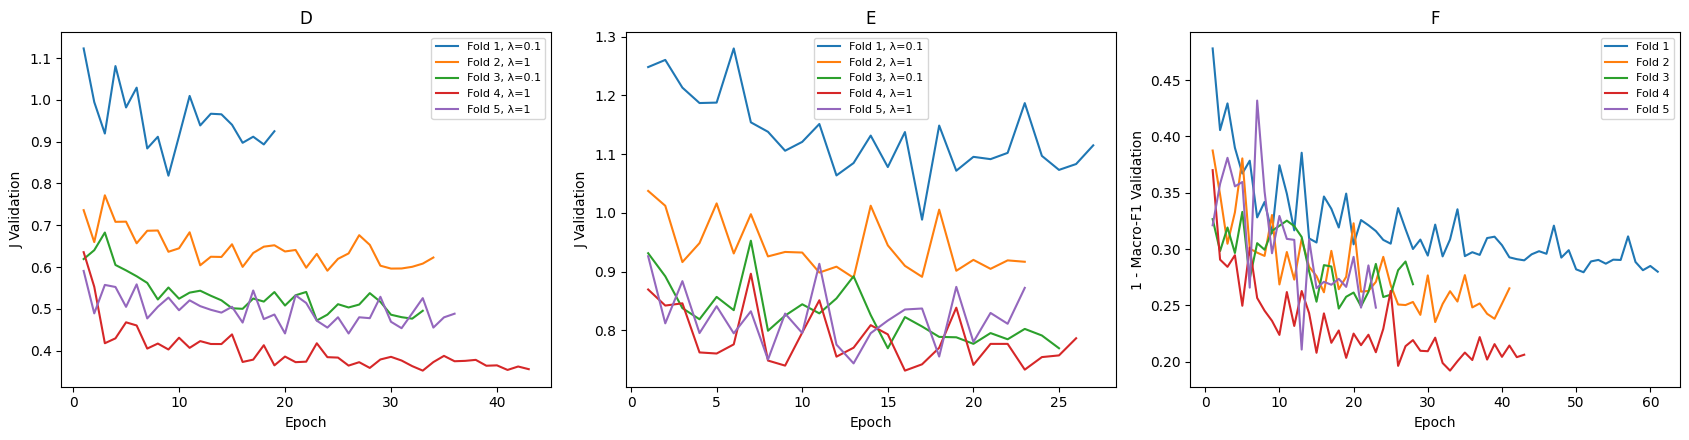

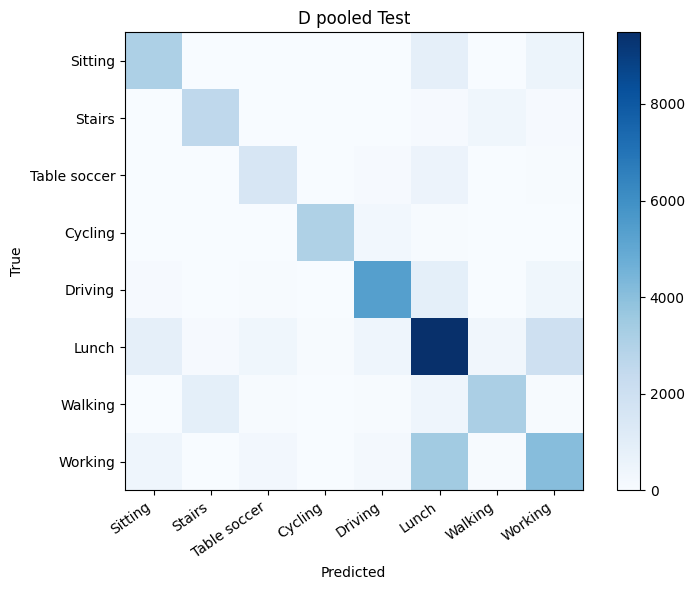

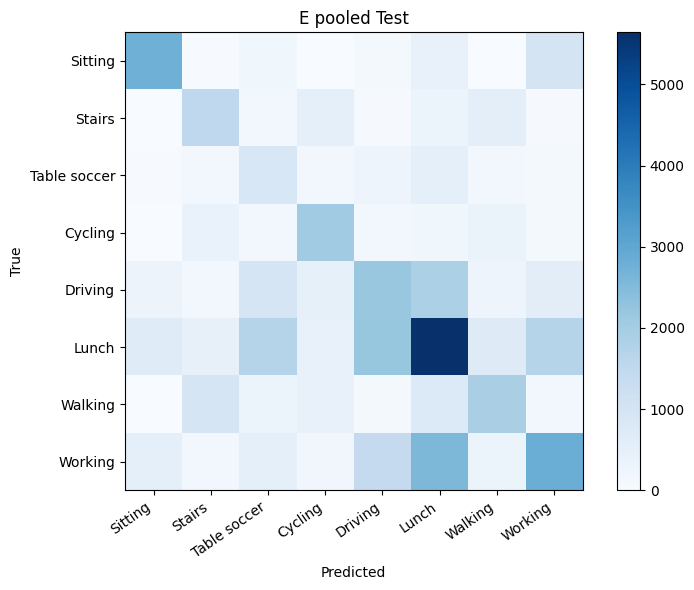

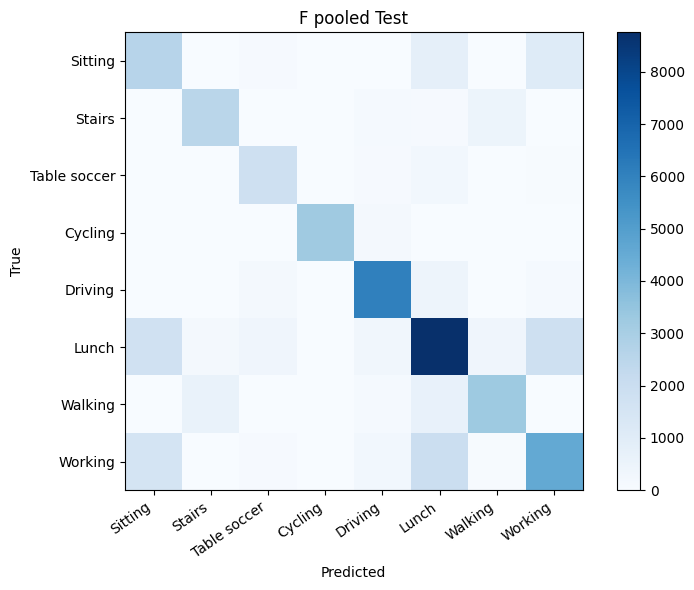

In [8]:
fig,axes=plt.subplots(1,3,figsize=(17,4.5))
for ax,variant in zip(axes,('D','E','F')):
    for row in run_df[run_df.variant==variant].itertuples():
        hist=pd.read_csv(OUT/f'{row.tag}_history.csv')
        ax.plot(hist.epoch,hist.criterion,label=f'Fold {row.fold}'+(f', λ={row.lam:g}' if variant!='F' else ''))
    ax.set(title=variant,xlabel='Epoch',ylabel='J Validation' if variant!='F' else '1 - Macro-F1 Validation')
    ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/'learning_curves_DEF.png',dpi=180);plt.show()
for variant in ('D','E','F'):
    cm=pd.read_csv(OUT/f'{variant}_confusion.csv',index_col=0)
    fig,ax=plt.subplots(figsize=(8,6));im=ax.imshow(cm,cmap='Blues');fig.colorbar(im,ax=ax)
    ax.set(xticks=range(8),yticks=range(8),xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES,
           title=f'{variant} pooled Test',xlabel='Predicted',ylabel='True')
    plt.setp(ax.get_xticklabels(),rotation=35,ha='right')
    fig.tight_layout();fig.savefig(OUT/f'{variant}_confusion.png',dpi=180);plt.show()

## 7. Chi phí suy luận

Đo checkpoint lượt 1 với batch 1, 50 warmup và 500 lần forward. M1/B2 được đo lại trong cùng phiên nếu còn checkpoint gốc trên Drive.


In [9]:
bench={};resource_rows=[]
for variant in ('D','E','F'):
    row=run_df[(run_df.fold==1)&(run_df.variant==variant)].iloc[0]
    ck=torch.load(row.path,map_location='cpu',weights_only=False)
    model=make_model(variant).to(DEVICE).eval();model.load_state_dict(ck['state'])
    bench[variant]=(model,len(VARIANTS[variant]['channels']))
for mode in ('M1','B2'):
    row=selection_main[(selection_main.fold==1)&(selection_main['mode']==mode)].iloc[0]
    path=MAIN/f'{row.tag}.pt'
    if not path.is_file():
        print(f'{mode}: không có checkpoint gốc để đo lại latency trong cùng phiên.');continue
    ck=torch.load(path,map_location='cpu',weights_only=False)
    assert ck.get('complete') and ck.get('config_hash')==PREP_HASH and not ck.get('smoke')
    assert ck['fold']==1 and ck['mode']==mode
    assert ck['epoch']==row.epoch and np.isclose(ck['score'],row.score)
    model=CNN(mode,4).to(DEVICE).eval();model.load_state_dict(ck['state']);bench[mode]=(model,4)
benchmark_id=datetime.datetime.now(datetime.timezone.utc).isoformat()
with torch.inference_mode():
    for name,(model,nc) in tqdm(bench.items(),desc='Tài nguyên',unit='mô hình'):
        state_path=OUT/f'{name}_fold1_inference_state.pt'
        state={k:v.detach().cpu() for k,v in model.state_dict().items()};torch.save(state,state_path)
        x=torch.zeros(1,nc,512,device=DEVICE)
        for _ in range(50):model(x)
        torch.cuda.synchronize();times=[]
        for _ in tqdm(range(500),desc=name,leave=False,unit='lần'):
            torch.cuda.synchronize();st=time.perf_counter();model(x);torch.cuda.synchronize()
            times.append((time.perf_counter()-st)*1000)
        resource_rows.append(dict(model=name,params=sum(p.numel() for p in model.parameters()),
                                  weights_bytes=state_path.stat().st_size,median_ms=float(np.median(times)),
                                  p95_ms=float(np.percentile(times,95)),device=torch.cuda.get_device_name(0),
                                  torch=torch.__version__,cuda=torch.version.cuda,benchmark_id=benchmark_id))
resource_df=pd.DataFrame(resource_rows);resource_df.to_csv(OUT/'resources_same_session.csv',index=False)
display(resource_df)
del bench;gc.collect();torch.cuda.empty_cache()

,model,params,weights_bytes,median_ms,p95_ms,device,torch,cuda,benchmark_id
0,D,422665,1705059,1.433774,2.404737,Tesla T4,2.11.0+cu130,13.0,2026-10-04T07:29:19.512100+00:00
1,E,421801,1701603,1.427611,3.260888,Tesla T4,2.11.0+cu130,13.0,2026-10-04T07:29:19.512100+00:00
2,F,405864,1636719,1.273856,3.214906,Tesla T4,2.11.0+cu130,13.0,2026-10-04T07:29:19.512100+00:00
3,M1,422665,1705097,1.435352,3.519160,Tesla T4,2.11.0+cu130,13.0,2026-10-04T07:29:19.512100+00:00
4,B2,406152,1637905,1.133060,1.899415,Tesla T4,2.11.0+cu130,13.0,2026-10-04T07:29:19.512100+00:00


## 8. Xuất kết quả

Tạo bảng tổng hợp và `M1_DEF_results.zip` gồm CSV, JSON và hình. Checkpoint và cache giữ trên Drive, không đưa vào ZIP.


In [10]:
assert len(run_df)==15 and set(pred.model)=={'D','E','F'}
for variant in ('D','E','F'):
    assert len(pred[pred.model==variant])==len(expected_keys)
needed=['test_predictions.csv','selected_before_test.json','comparison_deltas.csv','per_class_F1_deltas.csv',
        'HR_summary.csv','HAR_summary.csv','learning_curves_DEF.png','resources_same_session.csv']
assert all((OUT/name).is_file() for name in needed)
lines=['# Kết quả bổ sung D E F','',
       'D/E giữ λ từ Validation của M1 chính trong từng lượt; F là CNN-HAR chỉ ACC. '+
       'Tất cả dùng cùng Test và cùng cửa sổ hợp lệ.']
if SMOKE:
    lines+=['','**SMOKE: chỉ kiểm tra luồng chạy, không phải kết quả để nộp.**']
else:
    for variant in ('D','E','F'):
        hr=hr_df[hr_df.model==variant];har=har_df[har_df.model==variant].iloc[0]
        delta=comparison[comparison.experiment==variant].iloc[0]
        text=f"{variant}: Accuracy {har.accuracy:.4f}, Macro-F1 {har.macro_f1:.4f}; ΔMacro-F1 so với {delta.baseline}: {delta.delta_macro_f1:+.5f}."
        if not hr.empty:
            r=hr.iloc[0];text+=f" MAE theo người {r.MAE_subject:.3f} ± {r.SD_subject:.3f} bpm; ΔMAE {delta.delta_MAE_subject:+.3f} bpm."
        lines+=['',text]
    lines+=['','Chênh lệch chỉ mô tả một seed và năm nhóm người cố định; không tự kết luận có ý nghĩa thống kê.']
    lines+=['','Latency chỉ đối chiếu với baseline được đo trong cùng benchmark_id; nếu thiếu checkpoint gốc, chưa có đối chứng latency cùng phiên.']
summary='\n'.join(lines)
(OUT/'report_addendum.md').write_text(summary,encoding='utf-8');display(Markdown(summary))
status=pd.DataFrame([dict(experiment=k,models=5,status='SMOKE — không dùng để nộp' if SMOKE else 'Đã chạy và đánh giá Test',
                         baseline=VARIANTS[k]['baseline']) for k in ('D','E','F')])
status.to_csv(OUT/'protocol_completion.csv',index=False);display(status)
# Ensure the baseline files read by this notebook were not overwritten.
for name,expected in BASELINE_HASHES.items():
    assert hashlib.sha256((MAIN/name).read_bytes()).hexdigest()==expected, f'{name} đã đổi trong phiên'
(OUT/'completion.json').write_text(json.dumps(dict(complete=not SMOKE,smoke=SMOKE,models=15,
    windows_per_model=len(expected_keys),run_hash=RUN_HASH,finished_at=datetime.datetime.now(datetime.timezone.utc).isoformat()),indent=2))
archive=MAIN/('M1_DEF_results_SMOKE.zip' if SMOKE else 'M1_DEF_results.zip')
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    files=[p for p in OUT.rglob('*') if p.is_file() and p.suffix not in ('.pt','.npz','.part')]
    for path in tqdm(files,desc='Đóng gói CSV JSON hình',unit='file'):z.write(path,arcname=str(Path(OUT.name)/path.relative_to(OUT)))
print('Kết quả:',OUT,'| ZIP nhẹ:',archive)
print('Checkpoint vẫn giữ trên Drive để tiếp tục và kiểm tra suy luận.')
if not SMOKE:
    from google.colab import files
    files.download(str(archive))

# Kết quả bổ sung D E F

D/E giữ λ từ Validation của M1 chính trong từng lượt; F là CNN-HAR chỉ ACC. Tất cả dùng cùng Test và cùng cửa sổ hợp lệ.

D: Accuracy 0.6927, Macro-F1 0.7222; ΔMacro-F1 so với M1: -0.01301. MAE theo người 6.747 ± 3.870 bpm; ΔMAE +0.090 bpm.

E: Accuracy 0.4230, Macro-F1 0.4275; ΔMacro-F1 so với M1: -0.30768. MAE theo người 6.748 ± 2.949 bpm; ΔMAE +0.091 bpm.

F: Accuracy 0.7011, Macro-F1 0.7306; ΔMacro-F1 so với B2: -0.00055.

Chênh lệch chỉ mô tả một seed và năm nhóm người cố định; không tự kết luận có ý nghĩa thống kê.

Latency chỉ đối chiếu với baseline được đo trong cùng benchmark_id; nếu thiếu checkpoint gốc, chưa có đối chứng latency cùng phiên.

,experiment,models,status,baseline
0,D,5,Đã chạy và đánh giá Test,M1
1,E,5,Đã chạy và đánh giá Test,M1
2,F,5,Đã chạy và đánh giá Test,B2


Kết quả: /content/drive/MyDrive/M1_results/DEF | ZIP nhẹ: /content/drive/MyDrive/M1_results/M1_DEF_results.zip
Checkpoint vẫn giữ trên Drive để tiếp tục và kiểm tra suy luận.


## Kết quả và tài liệu tham khảo

D đạt MAE **6,747 ± 3,870 bpm**, Macro-F1 **0,7222**. E đạt MAE **6,748 ± 2,949 bpm**, Macro-F1 **0,4275**. F đạt Accuracy **70,11%**, Macro-F1 **0,7306**. Các chênh lệch chỉ mô tả năm nhóm người với seed 42; chưa có kiểm định thống kê.

- Đề cương M1, mục 4.3: D/E giữ λ của cấu hình chính; F chọn CNN-HAR chỉ ACC.
- [PPG-DaLiA tại UCI](https://archive.ics.uci.edu/dataset/495/ppg+dalia).
- [README dữ liệu](https://archive.ics.uci.edu/ml/machine-learning-databases/00495/readme.pdf).
- Reiss và cộng sự (2019), *Deep PPG*, Sensors 19(14), 3079. [DOI](https://doi.org/10.3390/s19143079).
